# K-means on autonomous trajectory data

The system is $y_{k+2}=(y_k+y_{k+1}^2)/2$. Each data vector is a complete
length-three trajectory $w=(y_0,y_1,y_2)$, obtained as a depth-three Hankel
column from an independently simulated rollout. We sample 12,000 training
initial conditions and 3,000 held-out initial conditions uniformly over
$y_0\in[-0.6,0.6]$, $y_1\in[-1,1]$, matching the shortened paper surface.
This is a selected patch of the behavior, not exhaustive data from every initial condition.
Independent short rollouts give coverage without the concentration near equilibria
that can arise from pooling long autonomous rollouts.

Euclidean K-means ($K=6$, 30 initializations, seed 20260929) operates directly on
all three trajectory coordinates, with no standardization or dimensionality reduction.
K-means returns labels and centroids, not linear subspaces. For each group, form
$W_j=[w^{(1)}\ \cdots\ w^{(N_j)}]$ and retain the first two left singular vectors
$U_j$ **without subtracting the mean**. The recorded linear subspace is
$\mathcal S_j=\operatorname{im}U_j=\{w:n_j^T w=0\}$, with projector $P_j=U_jU_j^T$.
It minimizes $\sum_{w\in C_j}\|w-P_jw\|_2^2$ among rank-two orthogonal projectors.

All six clusters have exact linear rank three: their exact spans are all
$\mathbb R^3$. The displayed planes are rank-two approximations. Every plane
passes through the origin; it is not a translated local tangent plane.
The K-means centroids are stored for assigning new trajectories, and are not
used as offsets in the linear models.



In [1]:
from pathlib import Path
import sys, json
import numpy as np
from IPython.display import Image, display
folder = Path.cwd()
if not (folder / "autonomous_behavioral_atlas.py").exists():
    folder = folder / "notebooks" / "motivation"
sys.path.insert(0, str(folder.resolve()))
from autonomous_behavioral_atlas import main, evaluate, OUT
RECOMPUTE = False
if RECOMPUTE or not (OUT / "autonomous_kmeans_atlas.npz").exists():
    main()
with np.load(OUT / "autonomous_kmeans_atlas.npz") as saved:
    data = dict(saved)
train, test = data["train"], data["test"]
metrics = evaluate(train, test, data)
assert np.isclose(metrics["test_rms"], json.loads((OUT / "autonomous_kmeans_metrics.json").read_text())["test_rms"])
print(f"Training: {len(train)}; held-out: {len(test)}; K: {metrics['K']}")
print(f"Held-out RMS: {metrics['test_rms']:.5f}; global rank-two RMS: {metrics['global_rank_two_test_rms']:.5f}")

Training: 12000; held-out: 3000; K: 6
Held-out RMS: 0.03696; global rank-two RMS: 0.19450


## K-means groups and their linear approximations

Colors identify groups. Plane patches all include the origin. Each dot is a complete trajectory.

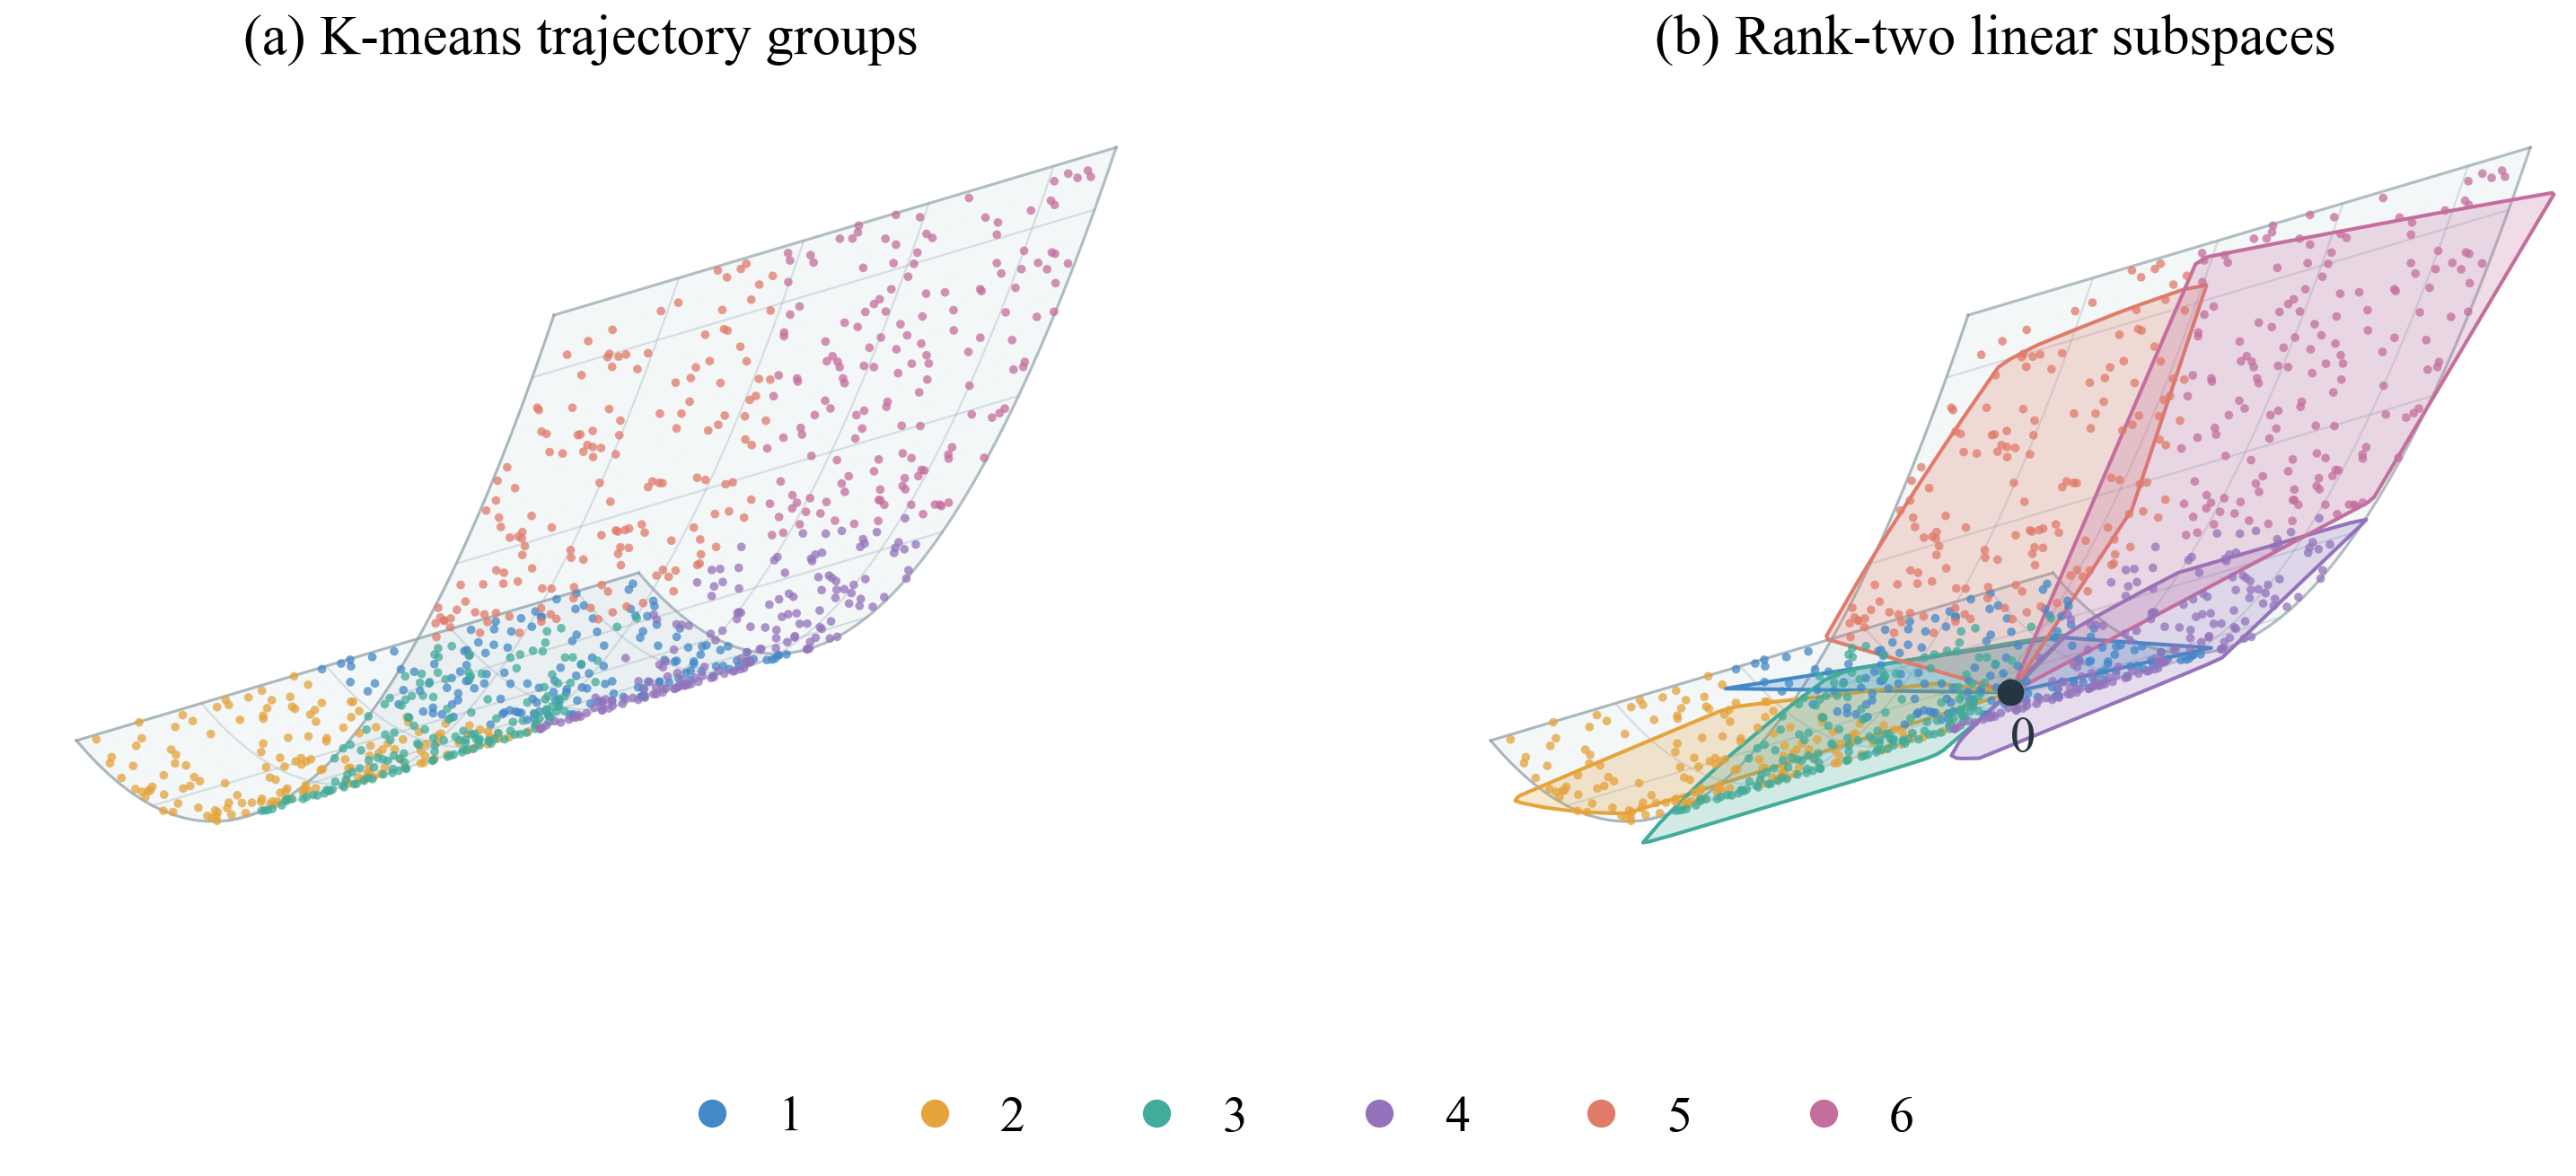

In [2]:
display(Image(filename=str(OUT / "autonomous_kmeans_overview.png"), width=950))

## Inspecting each subspace

Dots are true trajectories; shaded polygons lie in fitted linear planes. The black point is the origin. Gray segments show orthogonal projection errors. Only a subset of points is drawn to avoid clutter.

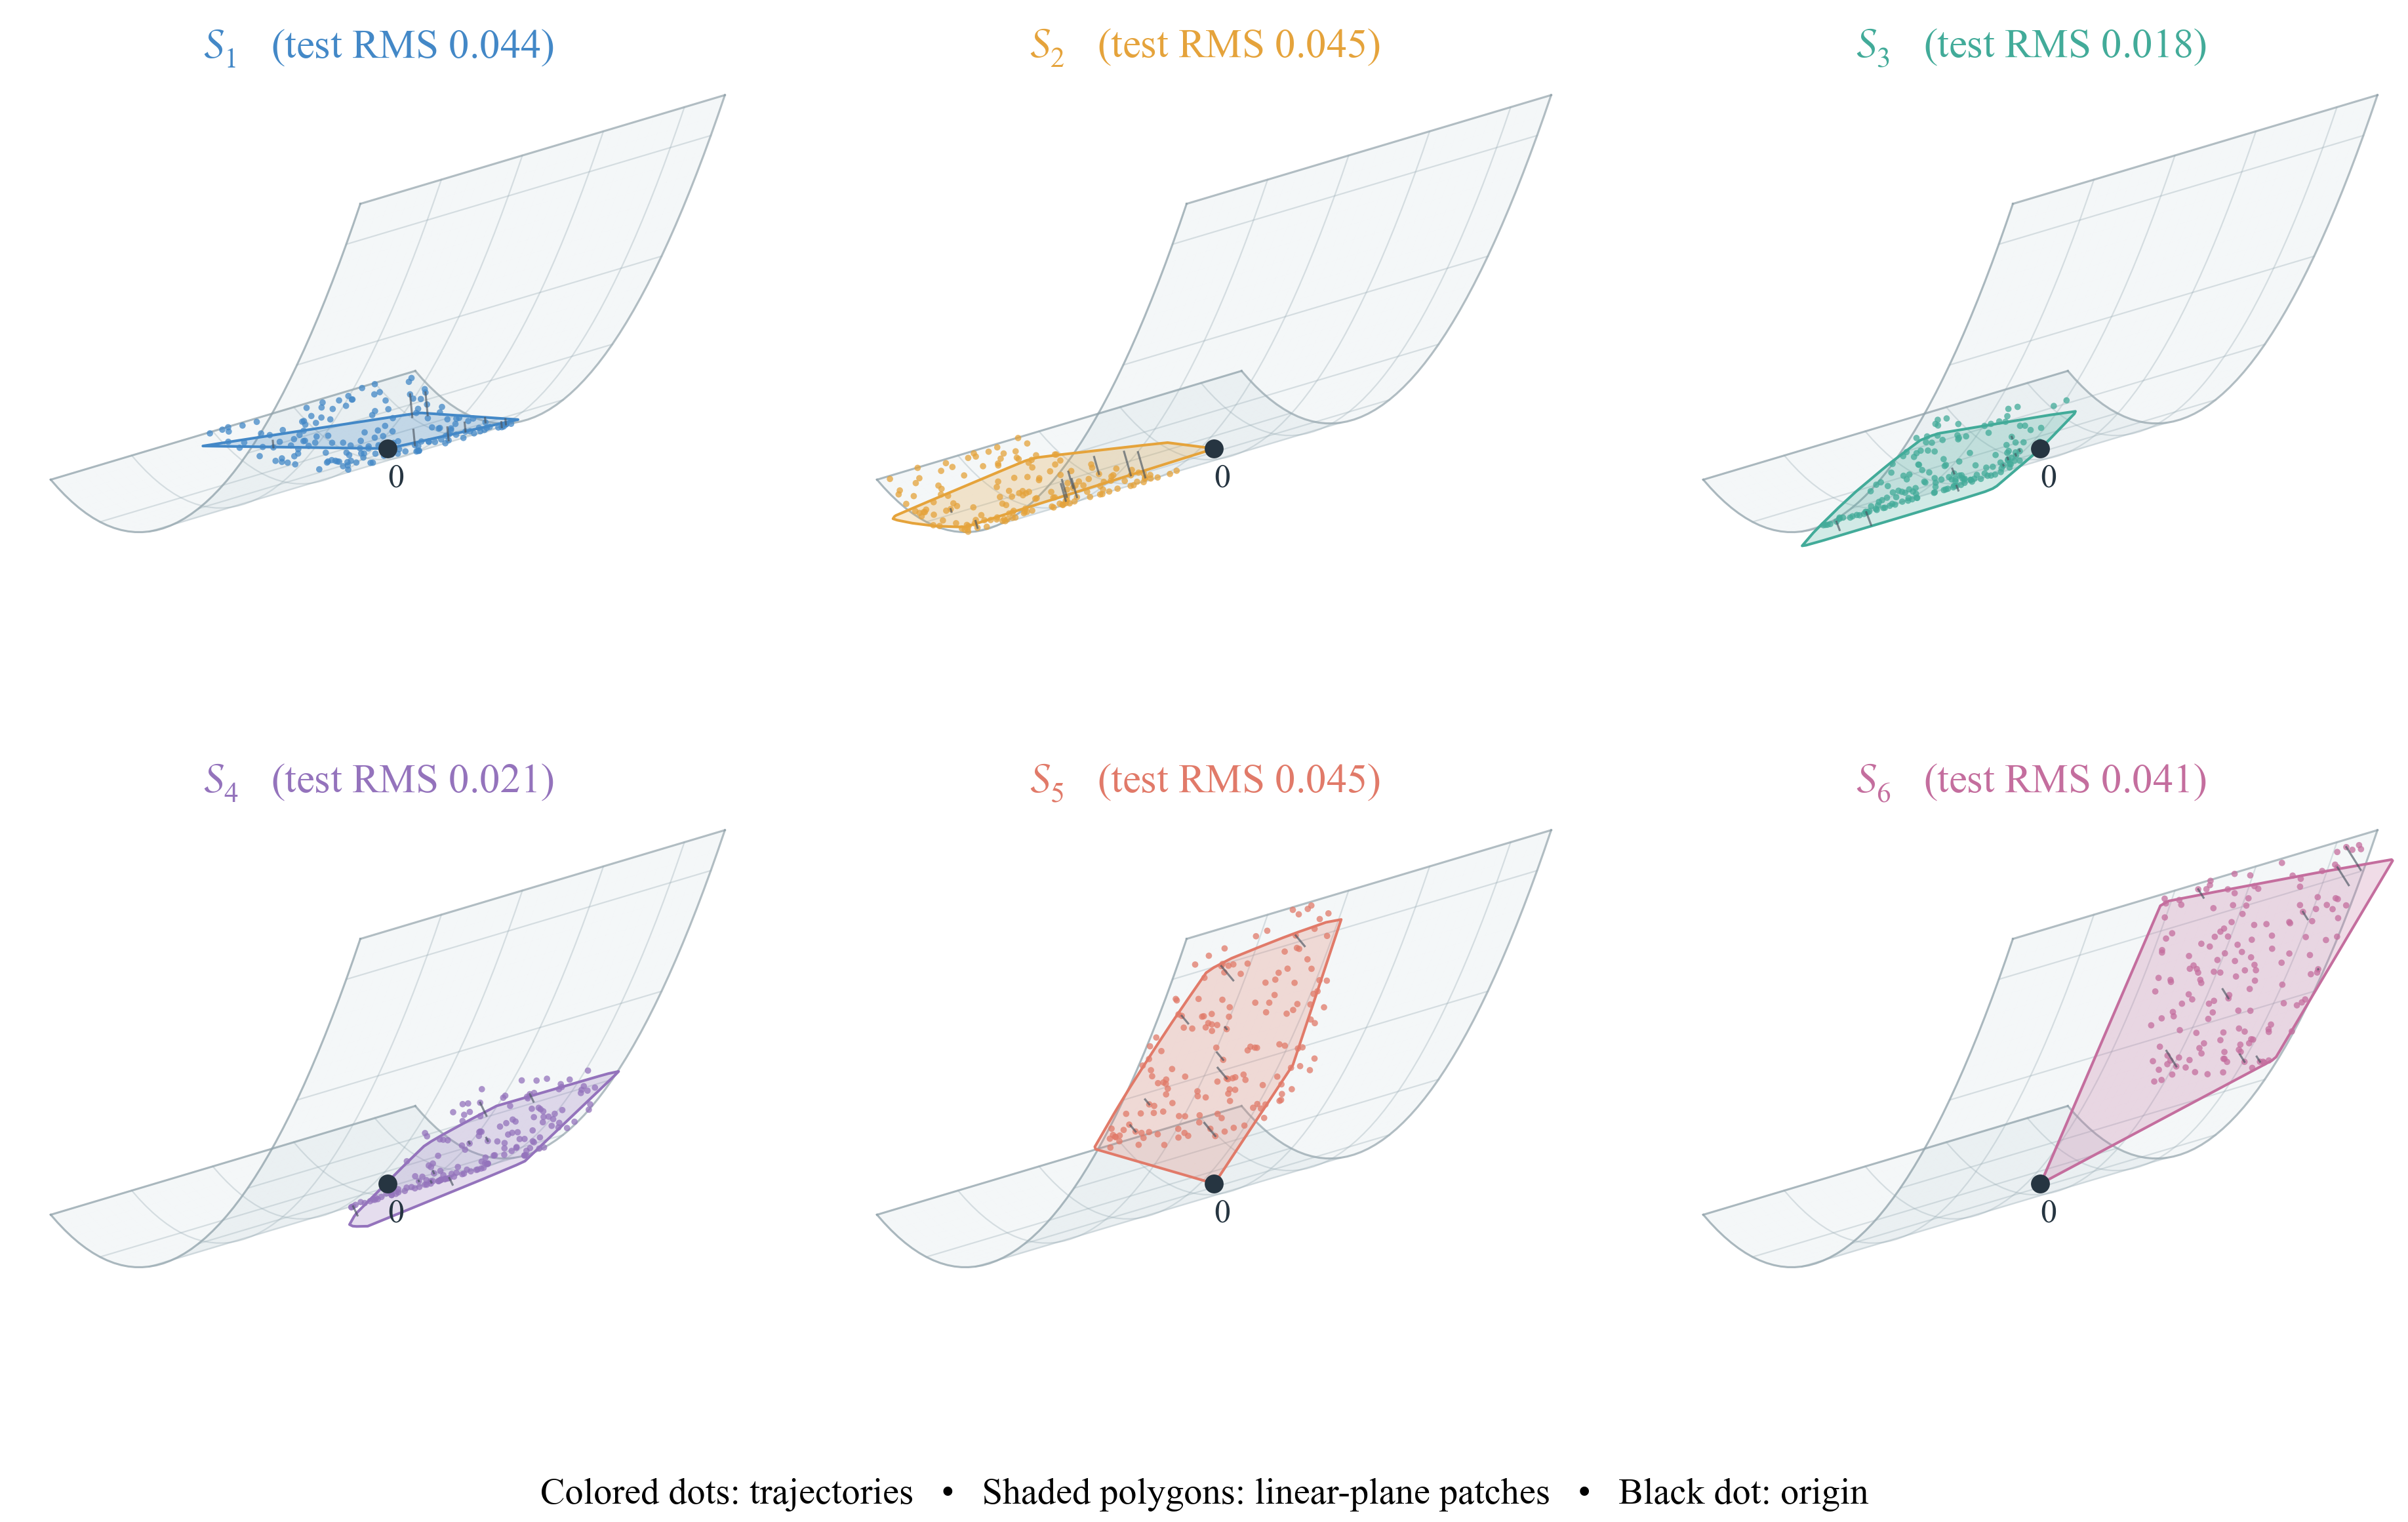

In [3]:
display(Image(filename=str(OUT / "autonomous_kmeans_subspaces.png"), width=1000))

## Recorded subspaces

| Group | Training windows | Plane equation ($n_j^T w=0$) | Test RMS |
|---|---:|---|---:|
| 1 | 1882 | $-0.3109y_0 +0.3899y_1 +0.8668y_2=0$ | 0.0439 |
| 2 | 1953 | $-0.4962y_0 +0.3442y_1 +0.7971y_2=0$ | 0.0452 |
| 3 | 2050 | $-0.4049y_0 +0.0036y_1 +0.9144y_2=0$ | 0.0183 |
| 4 | 2277 | $-0.4866y_0 -0.0214y_1 +0.8734y_2=0$ | 0.0211 |
| 5 | 1994 | $-0.4970y_0 -0.3440y_1 +0.7966y_2=0$ | 0.0449 |
| 6 | 1844 | $-0.3094y_0 -0.3941y_1 +0.8654y_2=0$ | 0.0407 |

Rounded equations are shown here; full precision is saved in NPZ and JSON. Each exact cluster span has dimension three.

In [4]:
for j in range(metrics["K"]):
    print(f"S_{j+1}: orthonormal basis U (columns), normal n")
    print(data["bases"][j])
    print(data["normals"][j])
    print()

S_1: orthonormal basis U (columns), normal n
[[-0.35362755  0.88219198]
 [ 0.79902395  0.45772692]
 [-0.48632118  0.11055941]]
[-0.31094191  0.38993179  0.86675736]

S_2: orthonormal basis U (columns), normal n
[[ 0.39921809  0.77101021]
 [ 0.90570504 -0.24748921]
 [-0.14255981  0.58676431]]
[-0.49615338  0.34416199  0.79711   ]

S_3: orthonormal basis U (columns), normal n
[[ 0.91422093 -0.01601539]
 [ 0.01911041  0.99981089]
 [ 0.40476523 -0.01103156]]
[-0.4048995   0.00360281  0.9143541 ]

S_4: orthonormal basis U (columns), normal n
[[ 0.87095302 -0.06856401]
 [ 0.06659078  0.99755146]
 [ 0.48683315 -0.01378644]]
[-0.48655916 -0.02137189  0.87338618]

S_5: orthonormal basis U (columns), normal n
[[-0.40315862  0.76837847]
 [ 0.90451133  0.25207775]
 [ 0.13900494  0.58826128]]
[-0.49704894 -0.34397101  0.79663435]

S_6: orthonormal basis U (columns), normal n
[[ 0.33402174  0.8903412 ]
 [ 0.80702471 -0.43972826]
 [ 0.48697084  0.11803224]]
[-0.30938977 -0.39414487  0.86540614]



Projection errors quantify geometric approximation, not predictive control performance. See [the report](autonomous_behavioral_atlas.md) for sampling details, definitions, and saved artifacts.

## Smaller K for readability

Use three groups on the identical 12,000 training and 3,000 held-out trajectories. All planes are still uncentered rank-two SVD fits. The six-group artifacts above are retained.

The K=3 figures use elevation 35 degrees and azimuth 160 degrees, exposing all three plane faces and their common origin. Only the display viewpoint changes; fitted subspaces and errors are unchanged.

The overview is formatted as a compact paper figure: 1.61 × 0.83 inches, tightly cropped on all sides, 8-point Times New Roman legend; panel titles omitted, vector PDF/SVG, and 600 dpi PNG. The linear fits and current view are unchanged.

Both overview panels show three subtle, unlabeled coordinate arrows through the true origin, marked $(0,0,0)$. The axes follow the same camera projection as the trajectories; the data and fitted subspaces are unchanged.

K=3 test RMS: 0.04493
K=6 test RMS: 0.03696


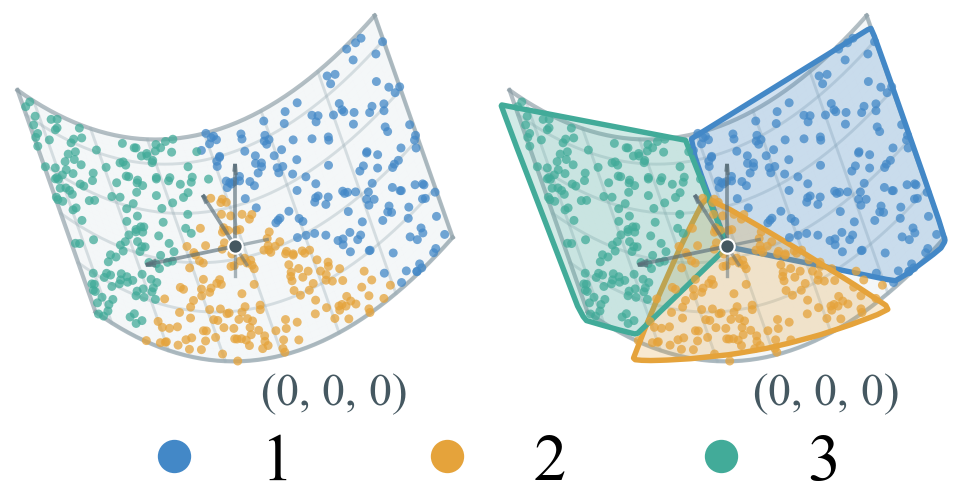

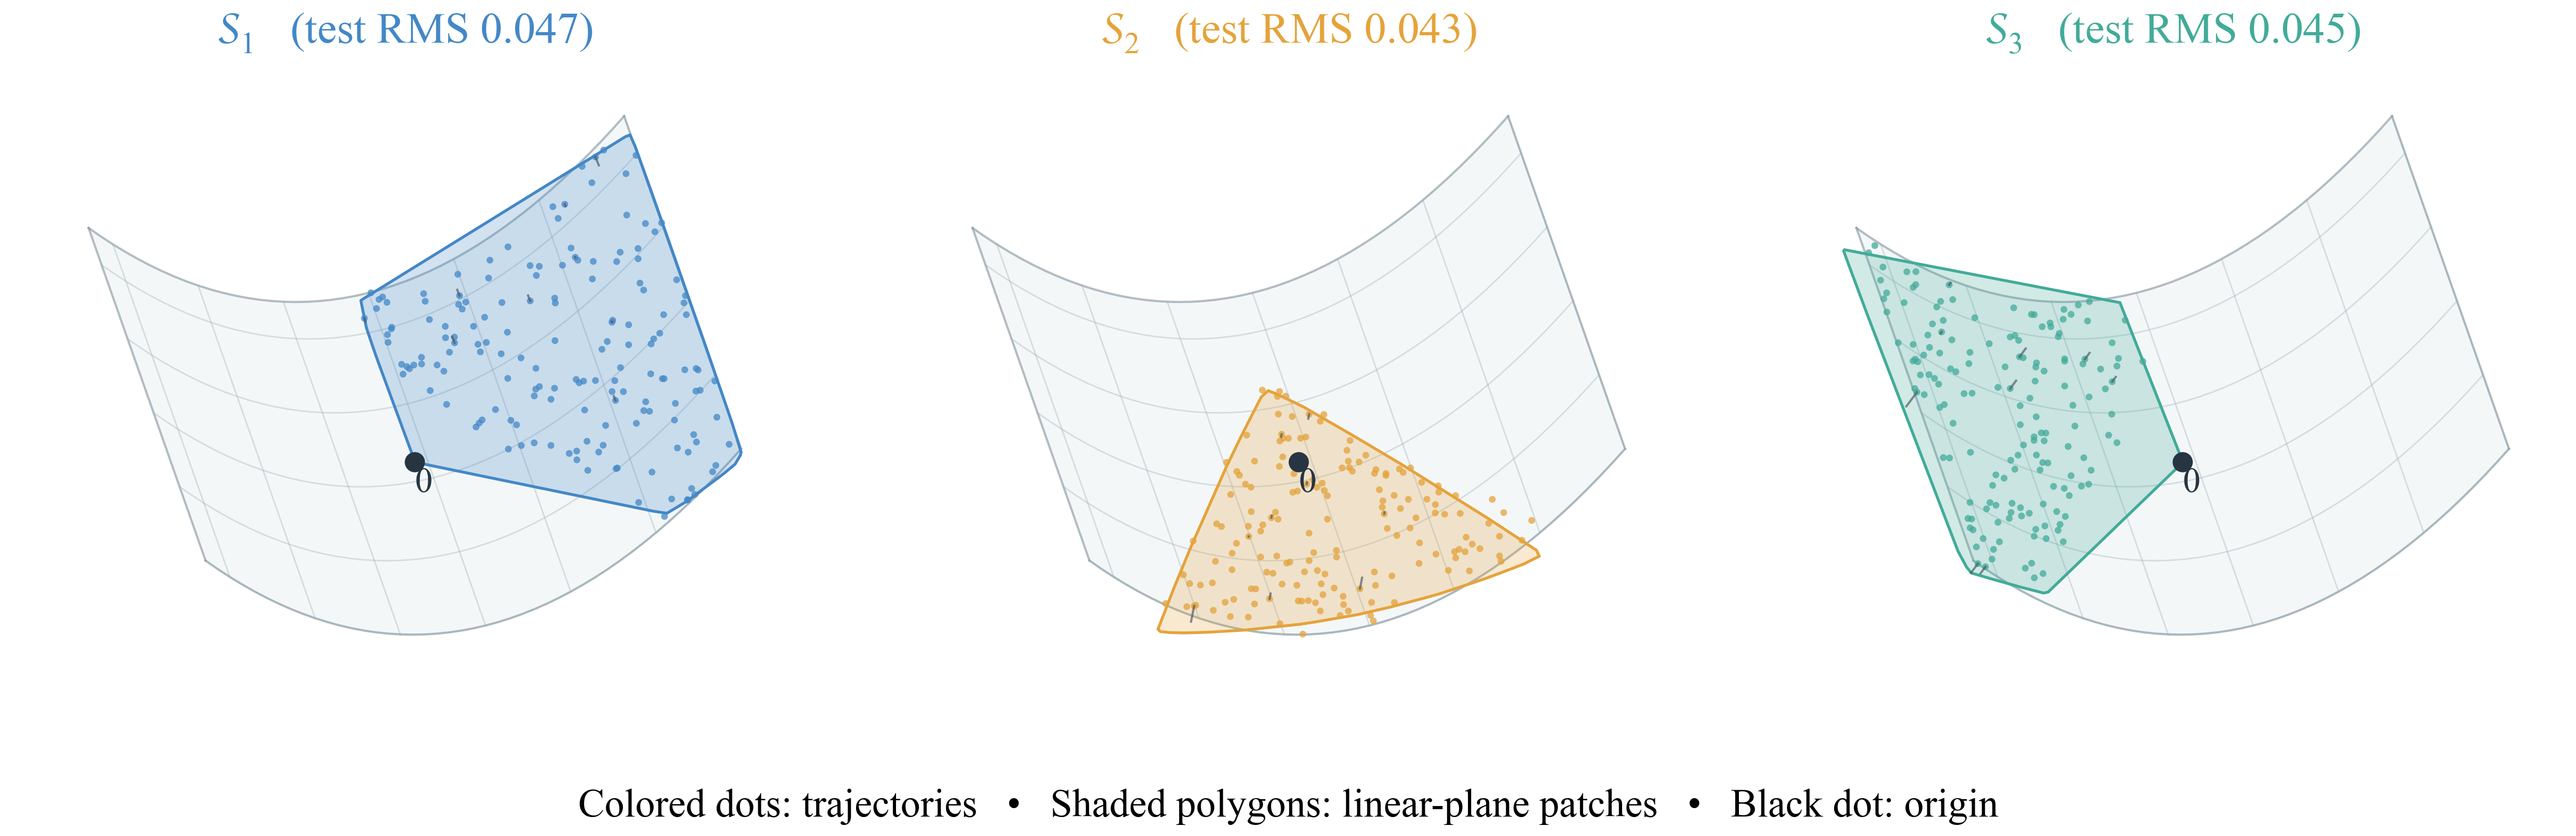

In [5]:
if RECOMPUTE or not (OUT / "autonomous_kmeans_k3_atlas.npz").exists():
    main(k=3)
with np.load(OUT / "autonomous_kmeans_k3_atlas.npz") as saved:
    data3 = dict(saved)
assert np.array_equal(data3["train"], train)
assert np.array_equal(data3["test"], test)
metrics3 = evaluate(train, test, data3)
print(f"K=3 test RMS: {metrics3['test_rms']:.5f}")
print(f"K=6 test RMS: {metrics['test_rms']:.5f}")
display(Image(filename=str(OUT / "autonomous_kmeans_k3_overview.png"), width=950))
display(Image(filename=str(OUT / "autonomous_kmeans_k3_subspaces.png"), width=1000))